# PassGuard - Intelligent Password Security Auditor and Policy Analysis System

**Course project - B.Tech CSE (Cybersecurity), 2nd year**

> **Privacy reminder:** every password in this notebook is **fictional test data**. The notebook prints only labels and derived measurements (length, entropy, score) - never a password. Never analyse a password from a real account with any tool you do not fully control.

## 1. Problem statement

People routinely choose short, predictable passwords (`123456`, `Password1!`, `qwerty123`) and organisations enforce **composition rules** that these passwords still satisfy. Users get little feedback on *why* a password is weak or how to improve it, and policy compliance is often mistaken for security.

PassGuard is a small, privacy-preserving tool that (1) analyses a password and explains its weaknesses, (2) estimates a *theoretical* entropy, (3) tracks improvement between an initial and a revised password, (4) simulates configurable password policies, and (5) produces a PDF audit report - without ever storing the password itself.

## 2. Objectives

1. Analyse a password for length, character classes, common-password matches and predictable patterns.
2. Estimate theoretical entropy with `H = L x log2(N)` and state clearly what that number does and does not mean.
3. Classify strength (Weak / Moderate / Strong / Very Strong) with a **heuristic** 0-100 score.
4. Compare an initial and a revised password using only derived results.
5. Let users configure a password policy and distinguish **policy compliance** from **strength**.
6. Generate a downloadable PDF report that contains no password.
7. Document and test everything reproducibly.

## 3. Libraries and their purposes

| Library | Purpose in PassGuard |
|---|---|
| **Python standard library** (`math`, `re`, `string`, `dataclasses`) | entropy maths, regular-expression pattern detection, character classes, policy objects |
| **Streamlit** | web interface (`app.py`) - not needed in this notebook |
| **Pandas** | summary tables of test results (without passwords) |
| **NumPy** | numeric helpers for the charts and summary statistics |
| **Matplotlib** | charts (score comparison, entropy vs length, ...) |
| **ReportLab** | PDF report generation (`report_generator.py`) |
| **zxcvbn** (optional) | independent guessability estimator used as a cross-check when installed |

No database is used: nothing sensitive is stored, and the non-sensitive results are small enough to live in memory. No machine-learning model is used - the analysis is rule-based.

## 4. Methodology and system workflow

```
 fictional password (masked input)
            |
            v
   password_analyzer.analyze_password()  --->  non-sensitive result dictionary
            |                                   (length, flags, entropy, score, weaknesses)
            |--> policy_simulator.evaluate_policy()   -> PASS / FAIL per rule
            |--> compare_assessments()                -> initial vs revised
            |--> report_generator.generate_pdf_report() -> PDF bytes (no password)
            v
   app.py (Streamlit) keeps ONLY result dictionaries in the browser session
```

Module responsibilities: `password_analyzer.py` (all analysis logic), `policy_simulator.py` (rules), `report_generator.py` (PDF), `app.py` (UI), this notebook and `test_password_analyzer.py` (documentation and verification).

## 5. The password-analysis algorithm

For each password `analyze_password()`:

1. Measures **length** and which **character classes** are present (lowercase, uppercase, digit, symbol).
2. Chooses the assumed **character-set size N** (26 + 26 + 10 + 33 for the classes present) and computes entropy.
3. Detects weaknesses:
   * exact match against a small **common-password list**; *variants* (e.g. `P@ssw0rd!` after undoing look-alike substitutions and stripping decorations); and *substrings* of common words
   * ascending/descending **sequences** (`abc`, `321`), **keyboard patterns** (`qwer`), **repeated characters** (`aaa`), **repeated blocks** (`abab`), and **years** (`2024`)
4. Computes a **heuristic score** out of 100:

   `score = entropy points (max 50) + length (max 20) + variety (max 20) + uniqueness (max 10) - pattern penalties`

   Caps then stop short or predictable passwords scoring highly (e.g. fewer than 8 characters -> at most 39; fewer than 14 characters -> never "Very Strong").
5. Maps the score to a label: `<40` Weak, `40-59` Moderate, `60-79` Strong, `>=80` Very Strong.
6. Produces specific weaknesses and recommendations.

**The score is a heuristic invented for this project. It is not a validated security measurement.**

## 6. Theoretical entropy and its assumptions

$$H = L \times \log_2(N)$$

* `L` = password length, `N` = assumed size of the character set.
* **Assumption:** every character is chosen **independently and uniformly at random** from the set.
* Real, human-chosen passwords are *not* random. `Summer2024!` has a large theoretical `H`, yet it is guessed very quickly because it follows a common pattern. So `H` is an **upper-bound style estimate for a randomly generated password**, not a measure of how guessable a human-created password is.
* Character diversity alone does not guarantee security. Long, unpredictable, unique passwords are preferred - which is why PassGuard also shows an independent `zxcvbn` cross-check when it is installed.

## 7. Implementation - imports of the core functions

In [1]:
import os, sys
sys.path.insert(0, os.getcwd())          # the notebook must sit in the PassGuard folder

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

from reportlab import rl_config
from password_analyzer import (analyze_password, calculate_entropy, compare_assessments,
                               result_to_flat_row, STRENGTH_LEVELS, ENTROPY_NOTE, SCORE_NOTE)
from policy_simulator import PasswordPolicy, evaluate_policy, policy_vs_strength
from report_generator import generate_pdf_report

pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 160)
print("Imports OK. Common-password list loaded from data/common_passwords.txt")
print(SCORE_NOTE)

Imports OK. Common-password list loaded from data/common_passwords.txt
The score is a heuristic created for this educational project. It is not a validated security measurement and a higher score does not guarantee real-world security.


A hand calculation of the entropy formula for a fictional 8-character password with lowercase, uppercase and digits (N = 26 + 26 + 10 = 62):

In [2]:
L, N = 8, 62
print(f"H = {L} x log2({N}) = {L * np.log2(N):.2f} bits (by hand)")
print(f"calculate_entropy({L}, {N}) = {calculate_entropy(L, N):.2f} bits (module function)")

H = 8 x log2(62) = 47.63 bits (by hand)
calculate_entropy(8, 62) = 47.63 bits (module function)


## 8. Fictional test cases

Passwords are kept in this list only as **test inputs**. Everything printed or tabulated afterwards uses the **label** and derived numbers - never the password.

In [3]:
TEST_CASES = [
    # (label, group, fictional password)
    ("Common numeric",          "Weak",     "123456"),
    ("Common word",             "Weak",     "letmein"),
    ("Common + substitutions",  "Weak",     "P@ssw0rd!"),
    ("Keyboard pattern",        "Weak",     "qwerty123"),
    ("Repeated characters",     "Weak",     "aaaa1111"),
    ("Sequence inside",         "Weak",     "Zk#abc9Pm"),
    ("Word + year + symbol",    "Moderate", "Summer2024!"),
    ("Short random (8)",        "Moderate", "Kp3mRt8x"),
    ("Two words + number (12)", "Stronger", "Coffee#Mug42"),
    ("Random 16 characters",    "Stronger", "Tr7#bQm9$Zw2!vPx"),
    ("Random-word passphrase",  "Stronger", "Purple-Maple-Rides-8-Bicycles!"),
]

rows = []
for label, group, pw in TEST_CASES:
    r = analyze_password(pw)
    rows.append({
        "Test case": label,
        "Expected group": group,
        "Length": r["length"],
        "Char types": r["character_types"],
        "Entropy (bits)": r["entropy_bits"],
        "Score /100": r["score"],
        "Strength": r["strength"],
        "zxcvbn 0-4": r["zxcvbn"]["score"] if r["zxcvbn"] else "n/a",
        "# weaknesses": len(r["weakness_codes"]),
        "Pattern weaknesses": ", ".join(c for c in r["weakness_codes"] if not c.startswith(("NO_", "LENGTH"))) or "none",
    })
df = pd.DataFrame(rows)
df

,Test case,Expected group,Length,Char types,Entropy (bits),Score /100,Strength,zxcvbn 0-4,# weaknesses,Pattern weaknesses
0,Common numeric,Weak,6,1,19.93,5,Weak,0,6,"COMMON_PASSWORD, SEQUENCE"
1,Common word,Weak,7,1,32.90,5,Weak,0,5,COMMON_PASSWORD
2,Common + substitutions,Weak,9,4,59.13,39,Weak,1,2,COMMON_VARIANT
3,Keyboard pattern,Weak,9,2,46.53,5,Weak,0,6,"COMMON_PASSWORD, SEQUENCE, KEYBOARD_PATTERN"
4,Repeated characters,Weak,8,2,41.36,28,Weak,1,4,REPEATED_CHARS
5,Sequence inside,Weak,9,4,59.13,56,Moderate,3,2,SEQUENCE
6,Word + year + symbol,Moderate,11,4,72.27,38,Weak,2,3,"COMMON_VARIANT, DATE_PATTERN"
7,Short random (8),Moderate,8,3,47.63,59,Moderate,2,2,none
8,Two words + number (12),Stronger,12,4,78.84,79,Strong,3,0,none
9,Random 16 characters,Stronger,16,4,105.12,100,Very Strong,4,0,none


### Test results summary (no passwords shown)

In [4]:
summary = df.groupby("Strength").size().reindex(STRENGTH_LEVELS, fill_value=0).rename("Count")
print(summary.to_string())
print()
print("Mean score by expected group:")
print(df.groupby("Expected group")["Score /100"].mean().round(1).reindex(["Weak", "Moderate", "Stronger"]).to_string())

Strength
Weak           6
Moderate       2
Strong         1
Very Strong    2

Mean score by expected group:
Expected group
Weak        23.0
Moderate    48.5
Stronger    91.7


In [5]:
# Does the heuristic order the test cases like the independent zxcvbn estimator?
# (Spearman rank correlation = Pearson correlation of the ranks.)
z = pd.to_numeric(df["zxcvbn 0-4"], errors="coerce")
if z.notna().all():
    rho = df["Score /100"].rank().corr(z.rank())
    print(f"Rank correlation between PassGuard score and zxcvbn score: {rho:.2f}")
else:
    print("zxcvbn is not installed - cross-check skipped (pip install zxcvbn to enable it).")

Rank correlation between PassGuard score and zxcvbn score: 0.95


## 9. Visualisations

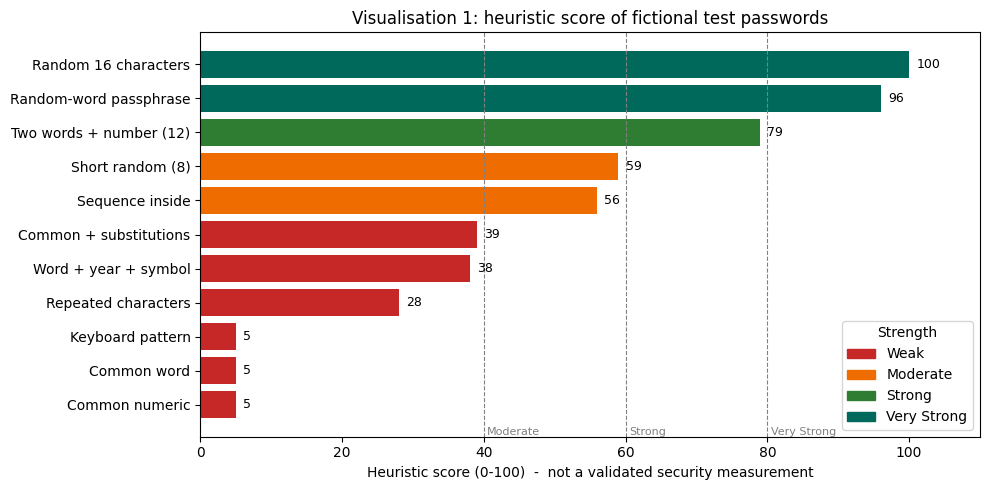

In [6]:
STRENGTH_COLORS = {"Weak": "#c62828", "Moderate": "#ef6c00", "Strong": "#2e7d32", "Very Strong": "#00695c"}

# Visualisation 1: heuristic score per test case, coloured by strength class
fig, ax = plt.subplots(figsize=(10, 5))
ordered = df.sort_values("Score /100")
bars = ax.barh(ordered["Test case"], ordered["Score /100"],
               color=[STRENGTH_COLORS[s] for s in ordered["Strength"]])
for bar, val in zip(bars, ordered["Score /100"]):
    ax.text(val + 1, bar.get_y() + bar.get_height() / 2, str(val), va="center", fontsize=9)
for threshold, name in ((40, "Moderate"), (60, "Strong"), (80, "Very Strong")):
    ax.axvline(threshold, color="grey", linestyle="--", linewidth=0.8)
    ax.text(threshold + 0.5, -0.9, name, fontsize=8, color="grey")
ax.set_xlim(0, 110)
ax.set_xlabel("Heuristic score (0-100)  -  not a validated security measurement")
ax.set_title("Visualisation 1: heuristic score of fictional test passwords")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in STRENGTH_COLORS.values()]
ax.legend(handles, STRENGTH_COLORS.keys(), title="Strength", loc="lower right")
plt.tight_layout()
plt.show()

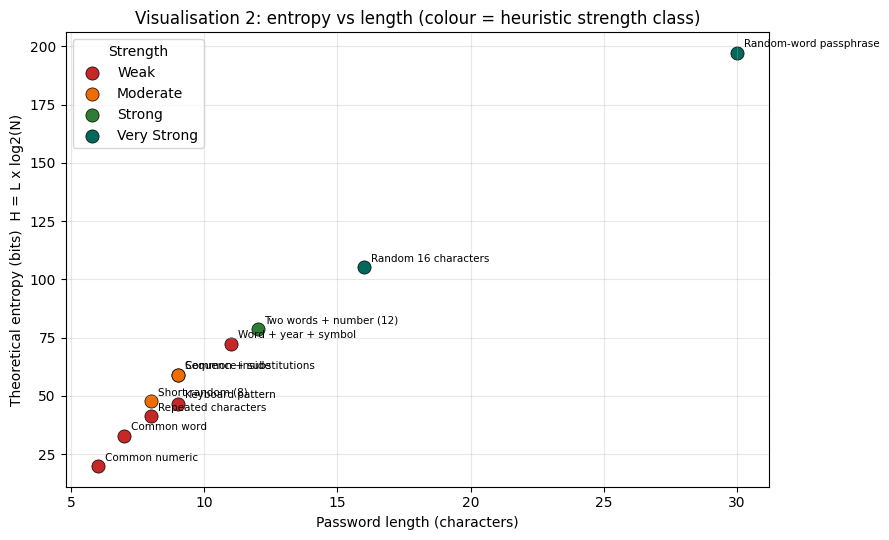

In [7]:
# Visualisation 2: theoretical entropy vs length - high entropy does not always mean a high score
fig, ax = plt.subplots(figsize=(9, 5.5))
for strength, color in STRENGTH_COLORS.items():
    part = df[df["Strength"] == strength]
    ax.scatter(part["Length"], part["Entropy (bits)"], s=90, color=color, label=strength,
               edgecolor="black", linewidth=0.5)
for _, row in df.iterrows():
    ax.annotate(row["Test case"], (row["Length"], row["Entropy (bits)"]), fontsize=7.5,
                xytext=(5, 4), textcoords="offset points")
ax.set_xlabel("Password length (characters)")
ax.set_ylabel("Theoretical entropy (bits)  H = L x log2(N)")
ax.set_title("Visualisation 2: entropy vs length (colour = heuristic strength class)")
ax.grid(alpha=0.3)
ax.legend(title="Strength")
plt.tight_layout()
plt.show()

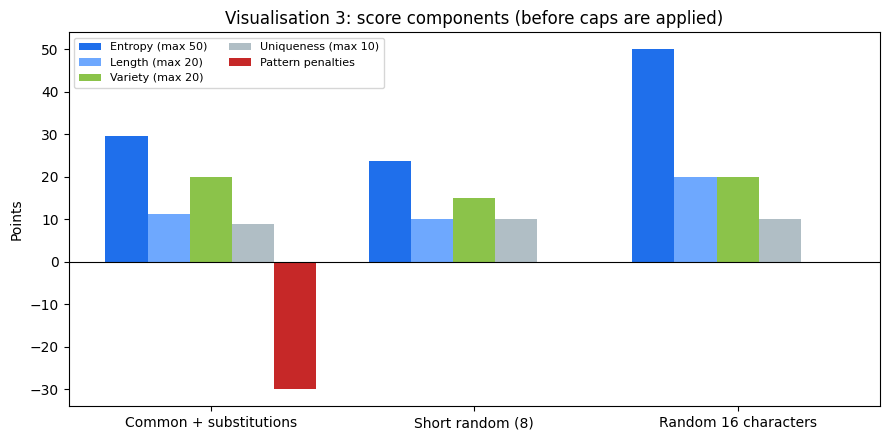

In [8]:
# Visualisation 3: how the score is built up for three contrasting cases
labels = ["Common + substitutions", "Short random (8)", "Random 16 characters"]
pw_by_label = {label: pw for label, _, pw in TEST_CASES}
parts = ["Entropy (max 50)", "Length (max 20)", "Variety (max 20)", "Uniqueness (max 10)", "Pattern penalties"]
colors = ["#1f6feb", "#6ea8fe", "#8bc34a", "#b0bec5", "#c62828"]
breakdowns = {lab: analyze_password(pw_by_label[lab])["score_breakdown"] for lab in labels}

fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(labels))
width = 0.16
for i, (part, color) in enumerate(zip(parts, colors)):
    ax.bar(x + (i - 2) * width, [breakdowns[lab][part] for lab in labels], width, label=part, color=color)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel("Points")
ax.set_title("Visualisation 3: score components (before caps are applied)")
ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

## 10. Improvement analytics demonstration

`compare_assessments()` works only on the derived result dictionaries - the two passwords are not needed afterwards.

In [9]:
pairs = [
    ("Common word -> random 16",    "letmein",  "Tr7#bQm9$Zw2!vPx"),
    ("Add a year and symbol only",  "Summer",   "Summer2024!"),
    ("Lengthen with a passphrase",  "Kp3mRt8x", "Purple-Maple-Rides-8-Bicycles!"),
]
rows = []
for name, before_pw, after_pw in pairs:
    c = compare_assessments(analyze_password(before_pw), analyze_password(after_pw))
    rows.append({
        "Scenario": name,
        "Strength": f"{c['initial_strength']} -> {c['latest_strength']}",
        "Score": f"{c['initial_score']} -> {c['latest_score']} ({c['score_change']:+d})",
        "Entropy change (bits)": c["entropy_change"],
        "Length change": c["length_change"],
        "Resolved": len(c["resolved_weaknesses"]),
        "Remaining": len(c["remaining_weaknesses"]),
        "New": len(c["new_weaknesses"]),
    })
improvement_df = pd.DataFrame(rows)
improvement_df

,Scenario,Strength,Score,Entropy change (bits),Length change,Resolved,Remaining,New
0,Common word -> random 16,Weak -> Very Strong,5 -> 100 (+95),72.22,9,5,0,0
1,Add a year and symbol only,Weak -> Weak,5 -> 38 (+33),38.07,5,4,0,3
2,Lengthen with a passphrase,Moderate -> Very Strong,59 -> 96 (+37),149.47,22,2,0,0


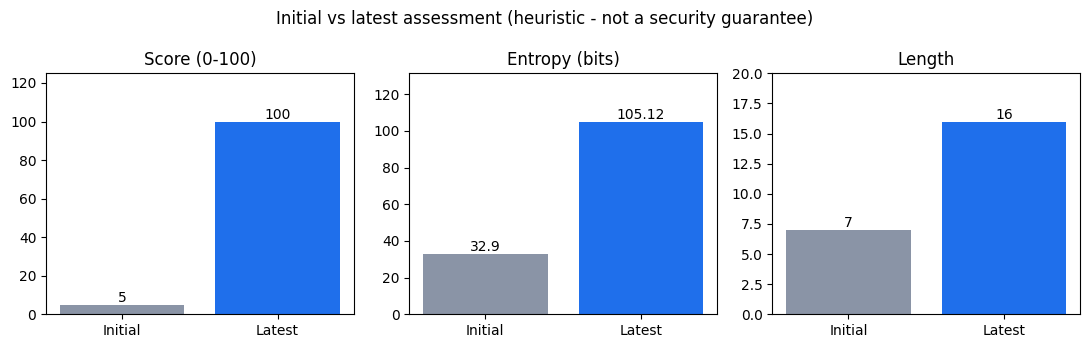

The heuristic score increased by 95 points (Weak -> Very Strong). A higher heuristic score does not guarantee better real-world security; the revised password must also be unique and unpredictable.


In [10]:
# Comparison chart for the first scenario
c = compare_assessments(analyze_password("letmein"), analyze_password("Tr7#bQm9$Zw2!vPx"))
fig, axes = plt.subplots(1, 3, figsize=(11, 3.5))
for ax, (title, a, b) in zip(axes, [("Score (0-100)", c["initial_score"], c["latest_score"]),
                                    ("Entropy (bits)", c["initial_entropy"], c["latest_entropy"]),
                                    ("Length", c["initial_length"], c["latest_length"])]):
    bars = ax.bar(["Initial", "Latest"], [a, b], color=["#8a94a6", "#1f6feb"])
    ax.set_title(title)
    ax.set_ylim(0, max(a, b) * 1.25)
    for bar, v in zip(bars, (a, b)):
        ax.text(bar.get_x() + bar.get_width() / 2, v, str(v), ha="center", va="bottom")
fig.suptitle("Initial vs latest assessment (heuristic - not a security guarantee)")
plt.tight_layout()
plt.show()
print(c["summary"])

## 11. Policy-simulator demonstrations

The key lesson: **policy compliance is not strength.** A password can pass every rule and still be predictable, and a good passphrase can fail a rigid rule set.

In [11]:
policies = {
    "Basic (8, upper+lower+digit)":   PasswordPolicy(8, True, True, True, False),
    "Strict (12, all types)":         PasswordPolicy(12, True, True, True, True),
    "Length-focused (16, no rules)":  PasswordPolicy(16, False, False, False, False),
}
demo_passwords = {
    "Capitalised word + 1 + !":       "Password1!",
    "Word + year + symbol":           "Summer2024!",
    "Random 16 characters":           "Tr7#bQm9$Zw2!vPx",
    "Lowercase passphrase":           "purple maple rides bicycles",
}
rows = []
for pw_label, pw in demo_passwords.items():
    analysis = analyze_password(pw)
    row = {"Password (label)": pw_label, "Strength": analysis["strength"], "Score": analysis["score"]}
    for pol_label, policy in policies.items():
        row[pol_label] = evaluate_policy(pw, policy)["passed"] and "PASS" or "FAIL"
    rows.append(row)
policy_df = pd.DataFrame(rows)
policy_df

,Password (label),Strength,Score,"Basic (8, upper+lower+digit)","Strict (12, all types)","Length-focused (16, no rules)"
0,Capitalised word + 1 + !,Weak,39,PASS,FAIL,FAIL
1,Word + year + symbol,Weak,38,PASS,FAIL,FAIL
2,Random 16 characters,Very Strong,100,PASS,PASS,PASS
3,Lowercase passphrase,Very Strong,85,FAIL,FAIL,PASS


In [12]:
# Rule-by-rule detail for one policy
detail = evaluate_policy("abcdef", policies["Strict (12, all types)"])
print("Overall:", "PASS" if detail["passed"] else "FAIL", f"({detail['passed_rules']}/{detail['total_rules']} rules)")
pd.DataFrame(detail["rules"])[["rule", "requirement", "status", "detail"]]

Overall: FAIL (1/5 rules)


,rule,requirement,status,detail
0,Minimum length,At least 12 characters,FAIL,Current length: 6
1,Uppercase letter,At least one A-Z,FAIL,None found
2,Lowercase letter,At least one a-z,PASS,Found
3,Digit,At least one 0-9,FAIL,None found
4,Special character,At least one non-alphanumeric character,FAIL,None found


In [13]:
verdict = policy_vs_strength(evaluate_policy("Password1!", policies["Strict (12, all types)"]),
                             analyze_password("Password1!"))
print(verdict["level"].upper(), "-", verdict["message"])
verdict = policy_vs_strength(evaluate_policy("Password1!", policies["Basic (8, upper+lower+digit)"]),
                             analyze_password("Password1!"))
print(verdict["level"].upper(), "-", verdict["message"])

ERROR - The password fails the policy and is rated 'Weak'.
WARNING - The password COMPLIES with the policy but is rated 'Weak'. Meeting composition rules does not make a password unpredictable.


## 12. PDF report check (privacy)

In [14]:
# Generate a report in memory and confirm that the fictional password is absent.
# Compression is switched off ONLY for this check so the bytes are searchable.
test_pw = "Zx9#fakeSecretQ!"
old = (rl_config.pageCompression, rl_config.useA85)
rl_config.pageCompression, rl_config.useA85 = 0, 0
try:
    analysis = analyze_password(test_pw)
    pdf = generate_pdf_report(analysis, evaluate_policy(test_pw, PasswordPolicy()))
finally:
    rl_config.pageCompression, rl_config.useA85 = old

print("PDF size (bytes):", len(pdf))
print("Looks like a PDF:", pdf.startswith(b"%PDF"))
print("Report title present (text searchable):", b"PassGuard Security Audit Report" in pdf)
print("Password found in PDF bytes:", test_pw.encode() in pdf)

PDF size (bytes): 9803
Looks like a PDF: True
Report title present (text searchable): True
Password found in PDF bytes: False


## 13. Results and discussion

* On average the scores rise from the Weak group to the Moderate group to the Stronger group (see the group means above and Visualisation 1). Common passwords, simple variants of common passwords, sequences and keyboard patterns were caught and penalised.
* **Two cases did not land in the group I expected in advance.** `Sequence inside` (a 9-character mixed password with one short sequence) scored *Moderate* because a single pattern costs a fixed 15 points; `Word + year + symbol` scored *Weak* because it is recognised as a variant of a common word. My "expected group" labels are only my own expectations, not ground truth - which is itself a limitation of evaluating a heuristic.
* **Entropy alone is misleading.** `Word + year + symbol` has a respectable theoretical entropy but follows a very common pattern, so PassGuard caps its score (Visualisation 2).
* Length is the strongest lever: the 16-character random password and the passphrase score highest. The rank correlation printed above compares the ordering with the independent `zxcvbn` estimator when it is installed; the two measures are related but not identical (for example they disagree on some word-based passwords).
* The improvement comparison shows that adding a year and a symbol to a common word does **not** resolve its core weakness, whereas moving to a long random or passphrase-style password resolves several weaknesses at once.
* The policy demonstration confirms that `Password1!` can **PASS** common composition policies while still being rated Weak, while a long lowercase passphrase can fail composition rules yet be rated strong - policy compliance and password strength are different questions.
* The PDF contains only derived values; the fictional password was not found in the report bytes.

## 14. Limitations and possible improvements

**Limitations**
* The common-password list is a small educational starter list, not a real breach corpus; PassGuard cannot know whether a password has appeared in a data breach.
* The score is a hand-designed heuristic; its weights and thresholds are not empirically validated.
* Entropy assumes random, independent characters; human-chosen passwords are less random. Word-based passwords such as `Coffee#Mug42` may be over-rated by the heuristic because it has no dictionary-word segmentation; the `zxcvbn` cross-check can disagree.
* No machine-learning model is used and no claim is made about real attack times.

**Possible improvements**
* Use a larger public password list or a k-anonymity breach-check service (requires network access and careful privacy design).
* Add dictionary-word and name segmentation, and evaluate several scoring schemes against a labelled dataset.
* Add a secure random password / passphrase generator.
* Localisation and accessibility improvements in the Streamlit UI.

## 15. Conclusion

PassGuard demonstrates a privacy-preserving, explainable approach to password assessment: it analyses a password, explains weaknesses, estimates *theoretical* entropy, tracks improvement, simulates policies and exports a report - all without storing the password. The results also illustrate an important security lesson: **long, unpredictable and unique passwords matter more than composition rules or a high-looking entropy number**, and no heuristic score should be treated as a guarantee of real-world security.